# Topical Lectures, Controls
## Real drone, part 4: step responses, predicted and measured

Andreas Freise, 28.10.2026

### Goal

This notebook is for the members of the group who are not at the drone, and for everybody afterwards. It closes the chain of the afternoon: part 2 measured what the drone reports, part 3 measured how fast it follows a velocity command and designed the position loop from that, and here we check how good the prediction was.

Part A predicts the step response in two ways: with the first order model of part 3, using the response time `tau` from the identification flight, and with the simulator of the morning, in which the velocity cascade of `2Dsim_04_velocity_loop` stands in for the firmware. Part B loads the flights your group saved (or the recorded reference flights) and puts the measured response next to the predictions, and the hold phase next to the noise and drift that part 2 measured with the motors off.

The simulated drone moves in `y` and `z`, the real drone flies the step along `x`: we compare the `y` of the simulator with the `x` of the drone.


In [1]:
# Importing packages
import numpy as np
import matplotlib.pyplot as plt
import module
import crazyflie

%matplotlib inline

MyName = "Andreas"

## Part A: the prediction

### The first order model with the measured response time

Part 3 fitted the velocity of the drone after a command step with a first order response and a dead time. The cell loads that identification run, from your group's `data/` or from the reference recording, and repeats the fit. With `tau` the model of part 3 predicts the step response for any pair of gains: `crazyflie.model_step_response(Kp, Kd, tau)`. The model knows the limit on the command, `v_max = 0.3 m/s`, and the dead time; it does not know the attitude loop, the air in the room or the noise.


In [ ]:
DATA_ID = 'data' if crazyflie.saved_runs('data', match='identify') else 'data/reference'
names_id = crazyflie.saved_runs(DATA_ID, match='identify')
if names_id:
    run_id = crazyflie.load_run(names_id[-1], DATA_ID)      # the latest identification flight
    fit = crazyflie.fit_tau(run_id)
    tau, delay = fit['tau_s'], fit['delay_s']
    print('identification run', names_id[-1], 'from', DATA_ID)
else:
    tau, delay = 0.3, 0.0
    print('no identification run found, using tau = 0.3 s as a placeholder')

try:
    ident = crazyflie.load_drone_id('data/drone_id.csv')
except crazyflie.DroneError:
    ident = crazyflie.analyse_sensor_id(crazyflie.load_sensor_id('data/reference/sensor_id_reference.csv'))
limits = crazyflie.gain_limits(ident)
print(f"sensor identification of {ident['uri'] or 'the drone'}: noise std x {ident['std_x_m']:.3f} m, "
      f"vx {ident['std_vx_mps']:.3f} m/s, drift {ident['drift_x_m']:+.3f} m in {ident['still_s']:.0f} s")

fig, ax = plt.subplots(figsize=(9, 4.5))
for omega0 in (1.5, 2.0, 3.0, 4.0):
    Kp, Kd = crazyflie.design_gains(tau, omega0=omega0, zeta=0.7)
    Kd = min(Kd, 0.0)
    t_m, x_m, _, cmd_m = crazyflie.model_step_response(Kp, Kd, tau, delay=delay)
    clamped = 100 * np.mean(np.abs(cmd_m[t_m >= 0]) >= 0.3 - 1e-9)
    ax.plot(t_m, x_m, label=f'omega0 = {omega0} rad/s: Kp = {Kp:+.2f}, Kd = {Kd:+.2f}, command at the limit {clamped:.0f}% of the step')
ax.axhspan(0.5 - 0.15, 0.5 + 0.15, color='0.92', zorder=0)
ax.axhline(0.5, color='k', lw=0.5, ls='--')
ax.set_xlim(-1, 8)
ax.set_xlabel('time since step [s]')
ax.set_ylabel('position from start [m]')
ax.set_title(f'first order model, tau = {tau:.2f} s, zeta = 0.7', fontsize=10)
ax.legend(loc='lower right', fontsize=8)
ax.grid()


### The simulator as the second model

The second prediction uses the cascade from `2Dsim_04_velocity_loop` with its position loop replaced by the controller that flies: the gains from part 3 and the limit of 0.3 m/s. The run follows the flight: 4 s holding the start position, a step of 0.5 m, 8 s more. Wind off, so that we compare controllers; drag on, because the real drone has air drag too.

Two things are not in this model either: the velocity loop of the simulator is our own PI loop, not the one in the firmware, and the simulated drone moves only in a plane. The two models should agree with each other where the first order model is good; where they differ, the simulator's inner loop has a different response time than the drone's.


In [2]:
# Calibration constants of your drone, measured in 2Dsim_02:
# copy the values printed at the end of that notebook here.
# The numbers below are those of the drone of "Andreas".
# Motor mixing helpers as in 2Dsim_04 and 2Dsim_05.
V_left_offset = -0.0027
V_hover = 0.5297
V_max = 1.0
V_min = 0

def set_v_nohover(drone, _V_left, _V_right):
    V_left = _V_left + V_left_offset
    V_right = _V_right
    fb_z = (V_left + V_right) / 2
    fb_phi = (V_left - V_right) / 2
    fb_z = max(V_min, min(fb_z, V_max))
    headroom = min(fb_z - V_min, V_max - fb_z)
    fb_phi = max(-headroom, min(fb_phi, headroom))
    drone.set_V(fb_z + fb_phi, fb_z - fb_phi)

def zphi2V(fb_z, fb_phi):
    return fb_z + fb_phi, fb_z - fb_phi


def simulate_step(Kp, Kd, Ki=0.0, v_max=0.3, step=0.5, hold_s=4.0, step_s=8.0, name=MyName):
    """The flight sequence in the simulator: hold, step the y target, hold.

    Returns t (seconds since the step), y, dy and the velocity command dy_cmd.
    """
    drone = module.Drone(name=name, wind=False, flight_range=(-3, -3, 3, 3))
    dT = drone.deltaT
    # Position loop: the controller that flies on the real drone (simulator y = drone x).
    y_pos_ctrl = module.PIDController(Kp=Kp, Ki=Ki, Kd=Kd, deltaT=dT)
    z_pos_ctrl = module.PIDController(Kp=-2.0, Ki=0, Kd=0, deltaT=dT)
    # Inner loops standing in for the firmware, as tuned in 2Dsim_04_velocity_loop.
    y_vel_ctrl = module.PIDController(Kp=0.5, Ki=0.02, Kd=0, deltaT=dT)
    z_vel_ctrl = module.PIDController(Kp=-3.0, Ki=-0.3, Kd=0, deltaT=dT)
    phi_ctrl = module.PIDController(Kp=0.2, Ki=0, Kd=0.04, deltaT=dT)
    v_max_cmd = 1.0                 # m/s, firmware limit on the inner velocity loop
    tilt_max = np.deg2rad(20)       # rad, firmware limit on the commanded tilt

    N = int(round((hold_s + step_s) / dT))
    t = np.arange(N) * dT - hold_s
    y = np.zeros(N)
    dy = np.zeros(N)
    dy_cmd = np.zeros(N)
    for i in range(N):
        state = drone.update()
        y[i], dy[i] = state.y, state.dy
        y_setpoint = step if t[i] >= 0 else 0.0
        dy_des = float(np.clip(y_pos_ctrl(state.y, state.dy, y_setpoint), -v_max, v_max))
        dz_des = float(np.clip(z_pos_ctrl(state.z, state.dz, 0.0), -v_max_cmd, v_max_cmd))
        tilt_des = float(np.clip(y_vel_ctrl(state.dy, 0, dy_des), -tilt_max, tilt_max))
        z_corr = z_vel_ctrl(state.dz, 0, dz_des)
        phi_fb = phi_ctrl(state.phi, state.dphi, tilt_des)
        hover_ff = V_hover / np.cos(state.phi)
        V_l, V_r = zphi2V(hover_ff + z_corr, phi_fb)
        set_v_nohover(drone, V_l, V_r)
        dy_cmd[i] = dy_des
    return t, y, dy, dy_cmd


def response_numbers(t, pos, step):
    """Rise time to 90 percent, overshoot and the largest error over the last 3 s.

    The same definitions as crazyflie.step_numbers uses for the flights.
    """
    after = t >= 0
    p, ta = pos[after], t[after]
    hit = p > 0.9 * step
    rise = ta[np.argmax(hit)] if hit.any() else None
    overshoot = max(0.0, p.max() - step)
    tail = ta >= ta[-1] - 3.0
    settle = np.abs(step - p[tail]).max()
    return rise, overshoot, settle

simulation Kp=-1.2 Kd=-0.6: rise to 90% 4.43 s, overshoot 0.002 m, last 3 s max |error| 0.034 m


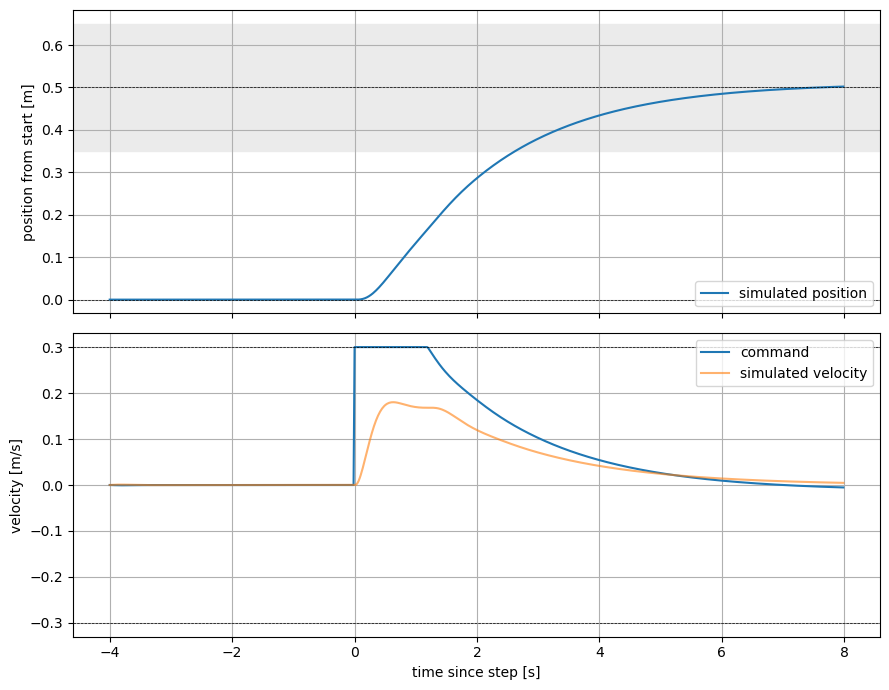

In [3]:
t_sim, y_sim, dy_sim, dy_cmd_sim = simulate_step(Kp=-1.2, Kd=-0.6)
rise, overshoot, settle = response_numbers(t_sim, y_sim, 0.5)
print(f"simulation Kp=-1.2 Kd=-0.6: rise to 90% {rise:.2f} s, overshoot {overshoot:.3f} m, "
      f"last 3 s max |error| {settle:.3f} m")

fig, ax = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
ax[0].plot(t_sim, y_sim, label='simulated position')
ax[0].axhspan(0.5 - 0.15, 0.5 + 0.15, color='0.92', zorder=0)
ax[0].axhline(0.5, color='k', lw=0.5, ls='--')
ax[0].axhline(0, color='k', lw=0.5, ls='--')
ax[0].set_ylabel('position from start [m]')
ax[0].legend(loc='lower right')
ax[0].grid()
ax[1].plot(t_sim, dy_cmd_sim, label='command')
ax[1].plot(t_sim, dy_sim, alpha=0.6, label='simulated velocity')
ax[1].axhline(0.3, color='k', lw=0.5, ls='--')
ax[1].axhline(-0.3, color='k', lw=0.5, ls='--')
ax[1].set_ylabel('velocity [m/s]')
ax[1].set_xlabel('time since step [s]')
ax[1].legend(loc='upper right')
ax[1].grid()
plt.tight_layout()

### Task: predict the effect of the gains

Run the simulation for `Kp = -0.8, -1.2, -1.6` with `Kd = 0`, then again with `Kd = -0.6`, and compare with the first order model for the same gains (`crazyflie.model_step_response`). Note the rise time and the overshoot in the table your group keeps for the flights, in a column *predicted*. Which gains do you expect to overshoot on the real drone? Which is the fastest setting that still settles within 15 cm? What do the gains correspond to in `omega0` and `zeta` for your `tau` (`crazyflie.closed_loop_parameters`)?


Kp=-0.8 Kd=+0.0: rise to 90% 4.65 s, overshoot 0.004 m, last 3 s max |error| 0.040 m
Kp=-1.2 Kd=+0.0: rise to 90% 3.58 s, overshoot 0.009 m, last 3 s max |error| 0.009 m


Kp=-1.6 Kd=+0.0: rise to 90% 3.17 s, overshoot 0.008 m, last 3 s max |error| 0.008 m
Kp=-0.8 Kd=-0.6: rise to 90% 6.18 s, overshoot 0.000 m, last 3 s max |error| 0.084 m
Kp=-1.2 Kd=-0.6: rise to 90% 4.43 s, overshoot 0.002 m, last 3 s max |error| 0.034 m
Kp=-1.6 Kd=-0.6: rise to 90% 3.72 s, overshoot 0.006 m, last 3 s max |error| 0.014 m


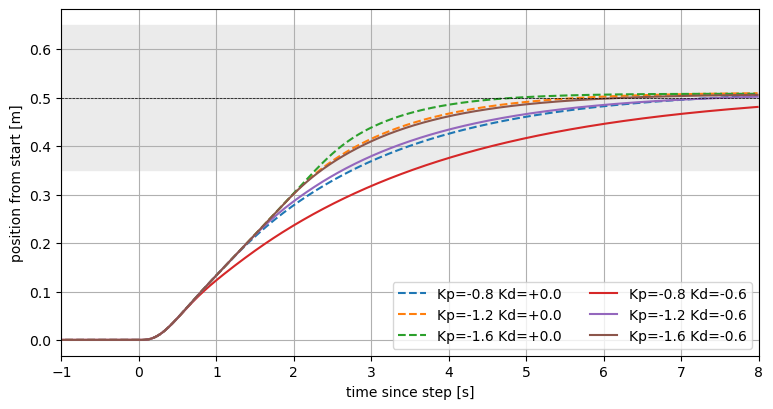

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for Kd in (0.0, -0.6):
    for Kp in (-0.8, -1.2, -1.6):
        t_s, y_s, _, _ = simulate_step(Kp=Kp, Kd=Kd)
        rise, overshoot, settle = response_numbers(t_s, y_s, 0.5)
        rise_text = f"{rise:.2f} s" if rise is not None else "not reached"
        print(f"Kp={Kp:+.1f} Kd={Kd:+.1f}: rise to 90% {rise_text}, overshoot {overshoot:.3f} m, "
              f"last 3 s max |error| {settle:.3f} m")
        ax.plot(t_s, y_s, ls='-' if Kd else '--', label=f'Kp={Kp:+.1f} Kd={Kd:+.1f}')
ax.axhspan(0.5 - 0.15, 0.5 + 0.15, color='0.92', zorder=0)
ax.axhline(0.5, color='k', lw=0.5, ls='--')
ax.set_xlim(-1, 8)
ax.set_xlabel('time since step [s]')
ax.set_ylabel('position from start [m]')
ax.legend(loc='lower right', ncol=2)
ax.grid()

## Part B: the measured flights

`crazyflie.saved_runs('data')` lists the runs saved in `data/` by name: drone label, time of the flight, run label. The reference runs in `data/reference` are from a test flight in September 2026 with `Kp = -1.2`, `Kd = -0.6`, on one axis (`reference_x`) and on both (`reference_xy`). The cell uses them as long as your group has no runs of its own.


In [5]:
DATA = 'data'               # your group's flights
labels = crazyflie.saved_runs(DATA)
if not labels:
    DATA = 'data/reference'
    labels = crazyflie.saved_runs(DATA)
print('runs in', DATA, ':', labels)
runs = [crazyflie.load_run(label, DATA) for label in labels]
runs = [r for r in runs if r['t_step'] is not None]
for r in runs:
    crazyflie.step_numbers(r)

runs in data/reference : ['reference_x', 'reference_xy']
reference_x
  x: rise to 90% 2.84 s, overshoot 0.049 m, last 3 s max |error| 0.049 m (mean -0.015 m), clamp 7% of step
  settle check (< 0.15 m on x): PASS
reference_xy
  x: rise to 90% 2.88 s, overshoot 0.016 m, last 3 s max |error| 0.016 m (mean -0.001 m), clamp 7% of step
  y: rise to 90% 3.13 s, overshoot 0.031 m, last 3 s max |error| 0.031 m (mean -0.014 m), clamp 7% of step
  settle check (< 0.15 m on xy): PASS


### Step responses

Position along each commanded axis relative to its start, against the time since the step, for all runs. The grey band is the target within 15 cm.


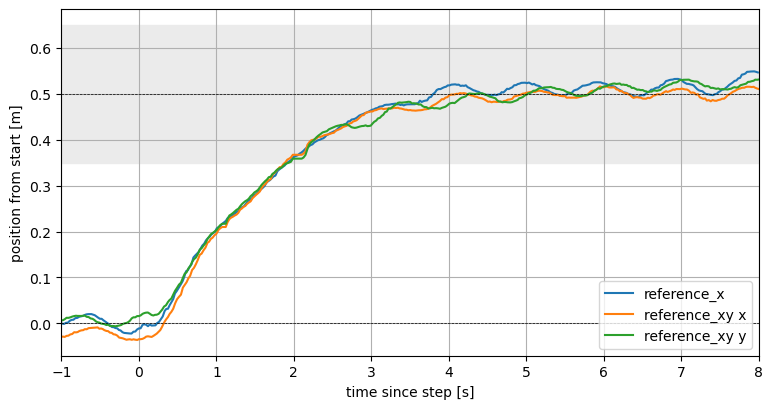

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for r in runs:
    pid = r['pid']
    t = pid['t_s'] - r['t_step']
    for a in r['axes']:
        name = r['label'] if len(r['axes']) == 1 else f"{r['label']} {a}"
        ax.plot(t, pid[a] - pid[f'target_{a}'][0], label=name)
ax.axhspan(0.5 - 0.15, 0.5 + 0.15, color='0.92', zorder=0)
ax.axhline(0.5, color='k', lw=0.5, ls='--')
ax.axhline(0, color='k', lw=0.5, ls='--')
ax.set_xlim(-1, 8)
ax.set_xlabel('time since step [s]')
ax.set_ylabel('position from start [m]')
ax.legend(loc='lower right')
ax.grid()

### Commanded against measured velocity

The command of the position loop against the velocity the estimator reports, one panel per run. The velocity loop of the firmware turns the one into the other; the lag between them is its response time. This is the loop that our PI loop in the simulator stands in for.

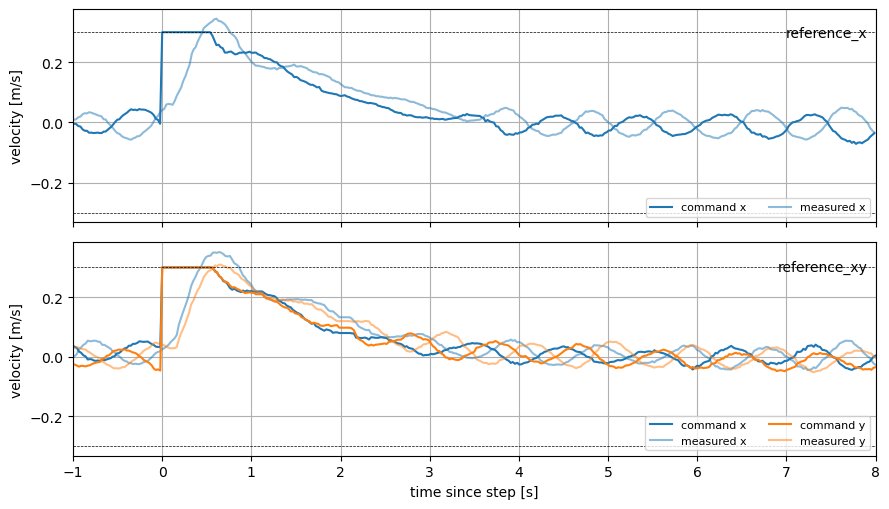

In [7]:
fig, panels = plt.subplots(len(runs), 1, figsize=(9, 2.6 * len(runs)), sharex=True, squeeze=False)
for panel, r in zip(panels[:, 0], runs):
    pid = r['pid']
    t = pid['t_s'] - r['t_step']
    for a in r['axes']:
        line, = panel.plot(t, pid[f'cmd_{a}'], label=f'command {a}')
        panel.plot(t, pid[f'v{a}'], color=line.get_color(), alpha=0.5, label=f'measured {a}')
    panel.axhline(0.3, color='k', lw=0.5, ls='--')
    panel.axhline(-0.3, color='k', lw=0.5, ls='--')
    panel.set_ylabel('velocity [m/s]')
    panel.text(0.99, 0.92, r['label'], transform=panel.transAxes, ha='right', va='top')
    panel.legend(loc='lower right', ncol=2, fontsize=8)
    panel.grid()
panels[-1, 0].set_xlim(-1, 8)
panels[-1, 0].set_xlabel('time since step [s]')
plt.tight_layout()

### Measured against predicted

Pick one run and the gains it flew with, and put the simulated response on top of it.


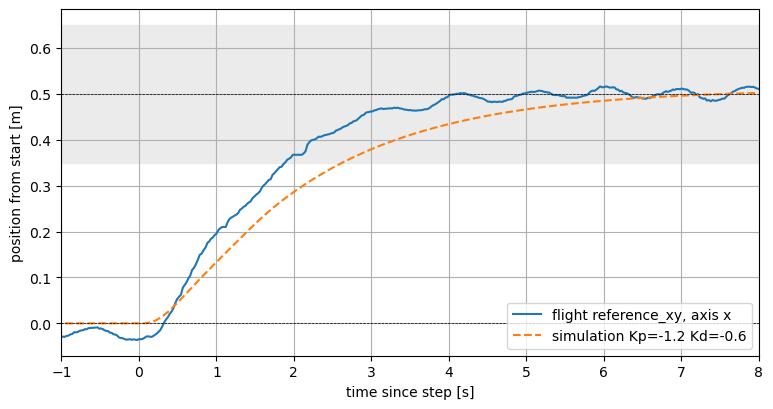

In [8]:
label = runs[-1]['label']       # the last run, change to the one you want
Kp_flown, Kd_flown = -1.2, -0.6  # the gains of that run, from your table

r = crazyflie.load_run(label, DATA)
a = r['axes'][0]
pid = r['pid']
t_meas = pid['t_s'] - r['t_step']
t_sim, y_sim, _, _ = simulate_step(Kp=Kp_flown, Kd=Kd_flown)
t_mod, x_mod, _, _ = crazyflie.model_step_response(Kp_flown, Kd_flown, tau, delay=delay)
w0, z = crazyflie.closed_loop_parameters(Kp_flown, Kd_flown, tau)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(t_meas, pid[a] - pid[f'target_{a}'][0], label=f'flight {label}, axis {a}')
ax.plot(t_mod, x_mod, 'k--', label=f'first order model, tau = {tau:.2f} s (omega0 = {w0:.1f} rad/s, zeta = {z:.2f})')
ax.plot(t_sim, y_sim, ls=':', label=f'simulator Kp={Kp_flown:+.1f} Kd={Kd_flown:+.1f}')
ax.axhspan(0.5 - 0.15, 0.5 + 0.15, color='0.92', zorder=0)
ax.axhline(0.5, color='k', lw=0.5, ls='--')
ax.axhline(0, color='k', lw=0.5, ls='--')
ax.set_xlim(-1, 8)
ax.set_xlabel('time since step [s]')
ax.set_ylabel('position from start [m]')
ax.legend(loc='lower right')
ax.grid()


### Tasks

1. Compare rise time and overshoot of the flight with the two predictions. Which is faster, and what in the real inner loops that the first order model leaves out (the dead time, the attitude loop, the limit on the tilt) could explain the difference?
2. During the hold before the step the real drone is not perfectly still. The cell below prints the standard deviation of the position during the hold next to the noise and the drift that part 2 measured with the motors off. The difference between the two is what the loop and the air in the room add. How do both compare with the 15 cm of the settling criterion?
3. The power log (`r['power']`, columns `pm.vbat` and `motor.m1` to `motor.m4`) shows how much motor headroom was left. What happens to the step response when the battery is low? Compare two runs of your group if you have them.
4. Optional: the sensor log (`r['sensor']`) has the raw flow counts `motion.deltaX` and `motion.deltaY` next to the estimated velocity. Plot one against the other to see what the Kalman filter on Day 2 has to work with.


reference_xy hold phase, axis x: std 1.7 cm over 3.4 s
reference_xy hold phase, axis y: std 0.8 cm over 3.4 s


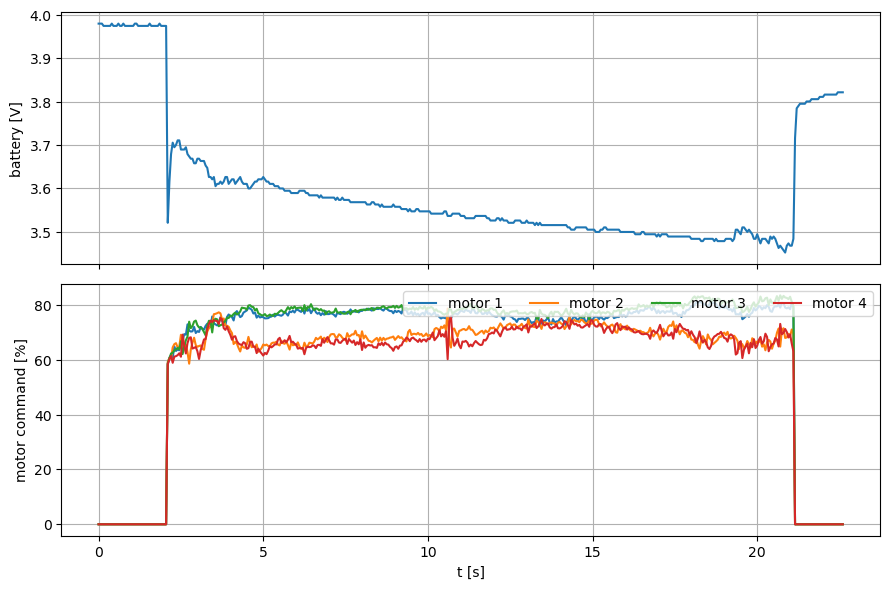

In [9]:
r = runs[-1]
pid = r['pid']
hold = pid['step'] < 0.5
for a in r['axes']:
    print(f"{r['label']} hold phase, axis {a}: std {100 * np.std(pid[a][hold]):.1f} cm "
          f"over {hold.sum() * 0.02:.1f} s, wander {100 * np.ptp(pid[a][hold]):.1f} cm")
print(f"motors off (part 2): std x {100 * ident['std_x_m']:.1f} cm, y {100 * ident['std_y_m']:.1f} cm, "
      f"drift {100 * ident['drift_x_m']:+.1f} cm, {100 * ident['drift_y_m']:+.1f} cm in {ident['still_s']:.0f} s")

if 'power' in r:
    p = r['power']
    tp = (p['t_ms'] - p['t_ms'][0]) / 1000.0
    fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
    ax[0].plot(tp, p['pm.vbat'])
    ax[0].set_ylabel('battery [V]')
    ax[0].grid()
    for i in (1, 2, 3, 4):
        ax[1].plot(tp, 100 * p[f'motor.m{i}'] / 65535, label=f'motor {i}')
    ax[1].set_ylabel('motor command [%]')
    ax[1].set_xlabel('t [s]')
    ax[1].legend(loc='upper right', ncol=4)
    ax[1].grid()
    plt.tight_layout()
